# Analyse exploratoire des données électriques — Mission 010

Projet M1 MIASHS 2026–2027. Analyse descriptive hors ligne de l'instantané acquis le 4 novembre 2026.

**Objectif :** décrire les puissances et la qualité des observations, sans entraînement, prévision,
création d'un jeu de variables prédictives ou modification des données préparées.

Deux scénarios demeurent distincts : **A**, étiquette de début de demi-heure ; **B**, étiquette de fin.
La nature moyenne et le support des mesures ODRÉ ne sont pas directement certifiés pour cet export.
Aucune comparaison descriptive ne permet de désigner une convention physique correcte.

## Sources et lecture

Source officielle documentée : [ODRÉ — Consommation quotidienne brute](https://odre.opendatasoft.com/explore/dataset/consommation-quotidienne-brute/),
attribution NaTran, RTE, Teréga ; série électrique RTE, France métropolitaine hors Corse, **MW**.
Le lien est une référence bibliographique : aucune requête réseau n'est exécutée.
La Licence Ouverte 2.0 et les limites de publication sont documentées dans les rapports locaux.

- [Audit des observations](../reports/audit_observations.json) et [diagnostic temporel](../reports/diagnostic_anomalies_temporelles.md).
- [Préparation demi-horaire](../reports/preparation_electricite_phase1.md).
- [Conventions et agrégation](../reports/etude_agregation_horaire.md).
- [Préparation horaire expérimentale](../reports/preparation_horaire_experimentale.md).

Le notebook s'exécute depuis la racine du projet, ou depuis `notebooks/`, avec le noyau Python `.venv`.
Utiliser « Exécuter tout » dans Jupyter ou VS Code. NumPy, pandas, Matplotlib et les bibliothèques
Jupyter déjà installées suffisent. Les données ignorées par Git doivent être présentes localement.
Les cellules lisent les sources et n'écrivent aucun fichier. Les figures intégrées sont également
fournies séparément dans `reports/figures/010_*.png` pour cette exécution.

In [1]:
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import hashlib
import json
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

get_ipython().run_line_magic('matplotlib', 'inline')
roots = [p for p in (Path.cwd(), Path.cwd().parent) if (p / 'AGENTS.md').is_file()]
assert roots, 'Exécuter depuis la racine du projet ou le dossier notebooks.'
ROOT = roots[0]
pd.set_option('display.max_rows', 35)
pd.set_option('display.max_columns', 14)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')
plt.rcParams.update({'figure.dpi': 90, 'savefig.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
COLORS = {'A': '#176b92', 'B': '#d46924'}
execution_utc = datetime.now(timezone.utc).isoformat()
display(pd.DataFrame({'outil': ['Python', 'NumPy', 'pandas', 'Matplotlib'],
                      'version observée': [platform.python_version(), np.__version__, pd.__version__, matplotlib.__version__]}))
print('Exécution UTC :', execution_utc)

,outil,version observée
0,Python,3.14.6
1,NumPy,2.5.4
2,pandas,3.1.0
3,Matplotlib,3.11.2


Exécution UTC : 2026-11-05T17:37:42.641251+00:00


## 1. Intégrité, provenance et schéma

Les quatre empreintes attendues proviennent des rapports de préparation et du manifeste d'acquisition.
La vérification porte sur les fichiers binaires, avant et après l'analyse. Le rapport d'audit brut est lu
comme résultat d'une exécution antérieure ; ses diagnostics ne sont pas présentés comme une nouvelle
lecture statistique de l'archive brute. La grille demi-horaire est parcourue pour contrôler ses étiquettes
et retrouver ses anomalies. Les CSV horaires existants ne sont pas recalculés.

In [2]:
expected_hashes = {
 'data/raw/odre_f6gejuyq/observations.json': '65f6a751d0e02d1a11c6d5e85dc620734b04ffc19f2c2ed3acc110e828125cf3',
 'data/processed/electricite_30min_phase1.jsonl': '50a3e89a7f9bbd5325ad1e4f557e6a3081ad7d5a429d6f9143f255b8f1172762',
 'data/processed/electricite_horaire_hypothese_debut.csv': '9208e6f00e0b1e9a5fc0ed69bcd69af023d54195defb3299656730c2100f3fb2',
 'data/processed/electricite_horaire_hypothese_fin.csv': '8c26a057d265e9ca627d4157e166aaf26b1a99f36b987521d1342218edf920b5',
}
observed_hashes = {}
for relative, expected in expected_hashes.items():
    with (ROOT / relative).open('rb') as stream:
        observed_hashes[relative] = hashlib.file_digest(stream, 'sha256').hexdigest()
    assert observed_hashes[relative] == expected, f'Empreinte inattendue : {relative}'
display(pd.DataFrame({'fichier relatif': list(observed_hashes), 'SHA-256 conforme': [True] * 4}))
audit_initial = json.loads((ROOT / 'reports/audit_observations.json').read_text(encoding='utf-8'))
assert audit_initial['input_sha256'] == expected_hashes['data/raw/odre_f6gejuyq/observations.json']
manifest = json.loads((ROOT / 'data/raw/odre_f6gejuyq/manifest.json').read_text(encoding='utf-8'))
assert manifest['status'] == 'complete' and manifest['sha256'] == audit_initial['input_sha256']
display(pd.DataFrame([{'observations brutes (audit antérieur)': audit_initial['rows'],
 'début brut UTC': audit_initial['all_rows_time']['start_utc'],
 'fin brute UTC': audit_initial['all_rows_time']['end_utc'],
 'téléchargement terminé UTC': manifest['completed_at_utc']}]))

paths = {'A': ROOT / 'data/processed/electricite_horaire_hypothese_debut.csv',
         'B': ROOT / 'data/processed/electricite_horaire_hypothese_fin.csv'}
schemas = {scenario: pd.read_csv(path, nrows=0).columns.tolist() for scenario, path in paths.items()}
assert schemas['A'] == schemas['B']
display(pd.DataFrame({'colonne disponible dans les deux CSV': schemas['A']}))

,fichier relatif,SHA-256 conforme
0,data/raw/odre_f6gejuyq/observations.json,True
1,data/processed/electricite_30min_phase1.jsonl,True
2,data/processed/electricite_horaire_hypothese_d...,True
3,data/processed/electricite_horaire_hypothese_f...,True


,observations brutes (audit antérieur),début brut UTC,fin brute UTC,téléchargement terminé UTC
0,258576,2011-12-31T23:00:00+00:00,2026-09-30T21:30:00+00:00,2026-11-04T15:44:02.514046+00:00


,colonne disponible dans les deux CSV
0,hour_start_utc
1,hour_end_utc
2,hour_start_local
3,electricity_mw
4,power_computable
5,target_eligible_strict
6,strict_electricity_mw
7,quality_reasons
8,source_timestamps_utc
9,source_positions


In [3]:
grid_counts = Counter()
grid_anomalies = []
previous = None
grid_first = None
with (ROOT / 'data/processed/electricite_30min_phase1.jsonl').open(encoding='utf-8') as stream:
    for line in stream:
        row = json.loads(line)
        stamp = datetime.fromisoformat(row['timestamp_utc'])
        assert stamp.utcoffset().total_seconds() == 0
        if previous is not None:
            assert (stamp - previous).total_seconds() == 1800
        grid_first = grid_first or stamp
        previous = stamp
        grid_counts['créneaux'] += 1
        grid_counts[row['quality_state']] += 1
        grid_counts['lignes sources'] += row['source_count']
        grid_counts['occurrences excédentaires'] += max(0, row['source_count'] - 1)
        grid_counts['statut manquant'] += int(row['has_missing_source_status'])
        if row['quality_state'] != 'unique' or row['has_missing_source_status'] or row['source_calendar_mismatch_count']:
            grid_anomalies.append({'utc': row['timestamp_utc'], 'état': row['quality_state'],
                                  'statut manquant': row['has_missing_source_status'],
                                  'discordances sources': row['source_calendar_mismatch_count']})
assert grid_counts['créneaux'] == 258574
assert grid_counts['lignes sources'] == audit_initial['rows']
assert grid_counts['occurrences excédentaires'] == audit_initial['all_rows_time']['duplicate_timestamp_excess']
assert grid_counts['absent'] == audit_initial['all_rows_time']['missing_halfhour_slots_between_grid_bounds']
assert grid_counts['duplicate_same_power'] == 11 and grid_counts['ambiguous'] == 22
display(pd.Series(grid_counts, name='contrôle de la grille demi-horaire').to_frame())
print('Grille UTC :', grid_first.isoformat(), 'à', previous.isoformat(), '; pas exact de 30 minutes.')

,contrôle de la grille demi-horaire
créneaux,258574
unique,258510
lignes sources,258576
occurrences excédentaires,33
statut manquant,1440
duplicate_same_power,11
ambiguous,22
absent,31


Grille UTC : 2011-12-31T23:00:00+00:00 à 2026-09-30T21:30:00+00:00 ; pas exact de 30 minutes.


In [4]:
frames = {}
quality_rows = []
reason_rows = []
usecols = ['hour_start_utc', 'hour_end_utc', 'hour_start_local', 'electricity_mw',
           'power_computable', 'target_eligible_strict', 'strict_electricity_mw',
           'quality_reasons', 'source_positions', 'source_timestamps_utc', 'timestamp_convention']
for scenario, path in paths.items():
    frame = pd.read_csv(path, usecols=usecols, na_values=['null'], keep_default_na=False,
                        true_values=['true'], false_values=['false'],
                        dtype={'electricity_mw': 'float64', 'strict_electricity_mw': 'float64',
                               'power_computable': 'boolean', 'target_eligible_strict': 'boolean'})
    frame['hour_start_utc'] = pd.to_datetime(frame['hour_start_utc'], utc=True)
    frame['hour_end_utc'] = pd.to_datetime(frame['hour_end_utc'], utc=True)
    assert (pd.to_datetime(frame['hour_start_local'], utc=True) == frame['hour_start_utc']).all()
    frame = frame.set_index('hour_start_utc')
    assert frame.index.is_unique and frame.index.is_monotonic_increasing
    assert frame.index.equals(pd.date_range(frame.index[0], frame.index[-1], freq='h'))
    assert (frame['hour_end_utc'] - frame.index == pd.Timedelta(hours=1)).all()
    assert frame['electricity_mw'].notna().equals(frame['power_computable'].astype(bool))
    assert frame['strict_electricity_mw'].notna().equals(frame['target_eligible_strict'].astype(bool))
    assert np.isfinite(frame.loc[frame['power_computable'], 'electricity_mw']).all()
    assert (frame.loc[frame['target_eligible_strict'], 'strict_electricity_mw'] ==
            frame.loc[frame['target_eligible_strict'], 'electricity_mw']).all()
    assert frame['timestamp_convention'].eq('experimental_start_label' if scenario == 'A' else 'experimental_end_label').all()
    reasons = Counter()
    for encoded in frame['quality_reasons']:
        reasons.update({reason['code'] for reason in json.loads(encoded)})
    reason_rows.extend({'scénario': scenario, 'motif (une fois par heure)': key, 'heures': value}
                       for key, value in reasons.items())
    frames[scenario] = frame
    quality_rows.append({'scénario': scenario, 'heures de grille': len(frame),
                        'calculables': int(frame['power_computable'].sum()),
                        'non calculables': int((~frame['power_computable']).sum()),
                        'strictes': int(frame['target_eligible_strict'].sum()),
                        'calculables hors strict': int((frame['power_computable'] & ~frame['target_eligible_strict']).sum()),
                        'début UTC': frame.index[0].isoformat(), 'fin exclusive UTC': frame['hour_end_utc'].iloc[-1].isoformat()})
assert frames['A'].index.equals(frames['B'].index)
assert len(frames['A']) == 129286
quality_table = pd.DataFrame(quality_rows).set_index('scénario')
display(quality_table)
display(pd.DataFrame(reason_rows).sort_values(['scénario', 'motif (une fois par heure)']))

,heures de grille,calculables,non calculables,strictes,calculables hors strict,début UTC,fin exclusive UTC
scénario,,,,,,,
A,129286,129251,35,128532,719,2011-12-31T23:00:00+00:00,2026-09-30T21:00:00+00:00
B,129286,129233,53,128499,734,2011-12-31T23:00:00+00:00,2026-09-30T21:00:00+00:00


,scénario,motif (une fois par heure),heures
3,A,absent,17
2,A,ambiguous,18
1,A,duplicate_resolved_same_power,11
4,A,missing_rte_status,719
0,A,source_calendar_mismatch,15
8,B,absent,31
7,B,ambiguous,22
6,B,duplicate_resolved_same_power,11
10,B,missing_rte_status,720
9,B,mixed_source_statuses,4


## 2. Populations utilisées et exclusions

Les motifs peuvent se cumuler : leurs comptes ne s'additionnent pas pour obtenir le nombre d'heures exclues.
Un doublon résolu de même puissance est une information de provenance, pas une seconde demi-heure.
Une puissance manquante (`null`) n'est jamais remplacée par zéro, interpolée ou moyennée avec une seule composante.

L'analyse principale utilise **l'intersection des heures strictes A et B**. Les deux statistiques portent
ainsi sur les mêmes instants UTC. « Strict » est la politique technique expérimentale déjà définie,
pas une preuve de justesse physique. Les heures à statut manquant et certaines discordances calendaires
sont exclues du strict même lorsque leur puissance est calculable.

Trois bases sont conservées pour la sensibilité : chaque scénario sur ses heures calculables,
chaque scénario sur ses heures strictes propres, et l'intersection calculable A/B.
Les résumés généraux couvrent toute la période. Les profils calendaires utilisent **2012–2025**,
années civiles locales complètes, afin d'écarter la couverture partielle de 2026 ; les trous de qualité
demeurent. Tous les regroupements calendaires ci-dessous sont descriptifs, calculés en mémoire,
sans création de variables ou de fichiers destinés à un modèle.

In [5]:
hour_index = frames['A'].index
common_computable = (frames['A']['power_computable'] & frames['B']['power_computable']).astype(bool)
common_strict = (frames['A']['target_eligible_strict'] & frames['B']['target_eligible_strict']).astype(bool)
powers = pd.DataFrame({scenario: frame['electricity_mw'] for scenario, frame in frames.items()})
paired = powers.where(common_strict, axis=0)
valid = powers.loc[common_strict].copy()
local_index = hour_index.tz_convert('Europe/Paris')
full_years = np.asarray(local_index.year <= 2025)
profile_mask = common_strict & full_years
profile_data = powers.loc[profile_mask].copy()
profile_local = profile_data.index.tz_convert('Europe/Paris')
cohorts = []
for scenario, frame in frames.items():
    masks = {'calculables propres': frame['power_computable'], 'strictes propres': frame['target_eligible_strict'],
             'calculables communes': common_computable, 'strictes communes (analyse principale)': common_strict,
             'strictes communes 2012–2025 (profils)': profile_mask}
    for label, mask in masks.items():
        cohorts.append({'scénario': scenario, 'population': label, 'utilisées': int(mask.sum()),
                        'exclues de la grille commune': int((~mask).sum())})
cohort_table = pd.DataFrame(cohorts)
display(cohort_table)
display(pd.DataFrame({'A calculable': frames['A']['power_computable'],
                      'B calculable': frames['B']['power_computable']}).value_counts().rename('heures').to_frame())
print('Période locale des heures conservées pour les profils :',
      profile_local.min().isoformat(), 'à', profile_local.max().isoformat())

,scénario,population,utilisées,exclues de la grille commune
0,A,calculables propres,129251,35
1,A,strictes propres,128532,754
2,A,calculables communes,129227,59
3,A,strictes communes (analyse principale),128493,793
4,A,strictes communes 2012–2025 (profils),122665,6621
5,B,calculables propres,129233,53
6,B,strictes propres,128499,787
7,B,calculables communes,129227,59
8,B,strictes communes (analyse principale),128493,793
9,B,strictes communes 2012–2025 (profils),122665,6621


,,heures
A calculable,B calculable,
True,True,129227
False,False,29
True,False,24
False,True,6


Période locale des heures conservées pour les profils : 2012-01-01T00:00:00+01:00 à 2025-12-31T23:00:00+01:00


## 3. Changements d'heure et couverture

Le temps de calcul est UTC ; les regroupements de calendrier utilisent `Europe/Paris`.
La durée théorique de chaque jour local est calculée entre deux minuits locaux successifs.
Les heures répétées restent deux instants distincts, avec leurs offsets. Une journée locale de 23 heures
ne justifie pas un trou dans la grille UTC, et une journée de 25 heures ne justifie pas une fusion.
La grille complète conserve les étiquettes même lorsque leur puissance est indisponible.

Le tableau affiche toutes les journées de transition couvertes ; les jours de bord incomplets sont
identifiés séparément. Les nombres de valeurs calculables/strictes sont calculés pour chaque scénario.

In [6]:
daily_base = pd.DataFrame({'date locale': local_index.date, 'étiquettes': 1,
                          'A calculables': frames['A']['power_computable'].to_numpy(dtype=bool),
                          'B calculables': frames['B']['power_computable'].to_numpy(dtype=bool),
                          'A strictes': frames['A']['target_eligible_strict'].to_numpy(dtype=bool),
                          'B strictes': frames['B']['target_eligible_strict'].to_numpy(dtype=bool),
                          'strictes communes': common_strict.to_numpy(dtype=bool)})
daily_quality = daily_base.groupby('date locale').sum()
midnights = pd.date_range(local_index[0].normalize(),
                         local_index[-1].normalize() + pd.DateOffset(days=1), freq='D')
expected_daily = pd.Series((midnights[1:].tz_convert('UTC') - midnights[:-1].tz_convert('UTC')).total_seconds() / 3600,
                           index=midnights[:-1].date, name='durée théorique (heures)')
daily_quality = daily_quality.join(expected_daily)
daily_quality['jour de bord incomplet'] = daily_quality['étiquettes'] != daily_quality['durée théorique (heures)']
transitions = daily_quality.loc[daily_quality['durée théorique (heures)'] != 24]
assert set(expected_daily.unique()) <= {23., 24., 25.}
assert len(transitions) == 29
display(transitions)
display(daily_quality.loc[daily_quality['jour de bord incomplet']])
print('Journées de transition :', len(transitions), '; aucune fusion ni heure synthétique ajoutée.')

,étiquettes,A calculables,B calculables,A strictes,B strictes,strictes communes,durée théorique (heures),jour de bord incomplet
date locale,,,,,,,,
2012-03-25,23,22,22,22,21,21,23.00,False
2012-10-28,25,24,23,24,23,23,25.00,False
2013-03-31,23,22,22,22,21,21,23.00,False
2013-10-27,25,24,23,24,23,23,25.00,False
2014-03-30,23,22,22,22,21,21,23.00,False
2014-10-26,25,24,23,24,23,23,25.00,False
2015-03-29,23,22,22,22,21,21,23.00,False
2015-10-25,25,24,23,24,23,23,25.00,False
2016-03-27,23,22,22,22,21,21,23.00,False


,étiquettes,A calculables,B calculables,A strictes,B strictes,strictes communes,durée théorique (heures),jour de bord incomplet
date locale,,,,,,,,
2026-09-30,23,23,23,0,0,0,24.00,True


Journées de transition : 29 ; aucune fusion ni heure synthétique ajoutée.


## 4. Évolution chronologique

La figure représente des **moyennes journalières descriptives de puissance**, pas des énergies.
Elles utilisent les heures strictes communes disponibles de chaque jour, avec au moins une valeur ;
aucun seuil de journée complète n'est imposé. Le troisième panneau donne le nombre d'heures contribuant
à chaque moyenne : une baisse de couverture doit être distinguée d'une baisse de consommation.
Les jours sans valeur demeurent manquants et interrompent les courbes.

Le tableau annuel fournit, pour chaque scénario, moyenne, effectif et exclusion de qualité par rapport
à la grille du fichier. L'année 2026 et la dernière journée sont partielles ; il ne s'agit ni de totaux
annuels d'énergie ni d'une comparaison causale des années.

,moyenne MW A,moyenne MW B,n utilisé A,n utilisé B,heures dans le fichier,exclues (masque commun),couverture calendaire
hour_start_utc,,,,,,,
2012,"55,399.59","55,399.95",8780,8780,8784,4,"année entière, exclusions qualité"
2013,"56,184.99","56,185.44",8756,8756,8760,4,"année entière, exclusions qualité"
2014,"52,781.95","52,782.80",8756,8756,8760,4,"année entière, exclusions qualité"
2015,"54,014.12","54,013.62",8756,8756,8760,4,"année entière, exclusions qualité"
2016,"54,682.96","54,684.18",8780,8780,8784,4,"année entière, exclusions qualité"
2017,"54,687.61","54,687.04",8756,8756,8760,4,"année entière, exclusions qualité"
2018,"54,282.63","54,283.09",8756,8756,8760,4,"année entière, exclusions qualité"
2019,"53,709.37","53,709.77",8755,8755,8760,5,"année entière, exclusions qualité"
2020,"50,725.94","50,726.69",8776,8776,8784,8,"année entière, exclusions qualité"


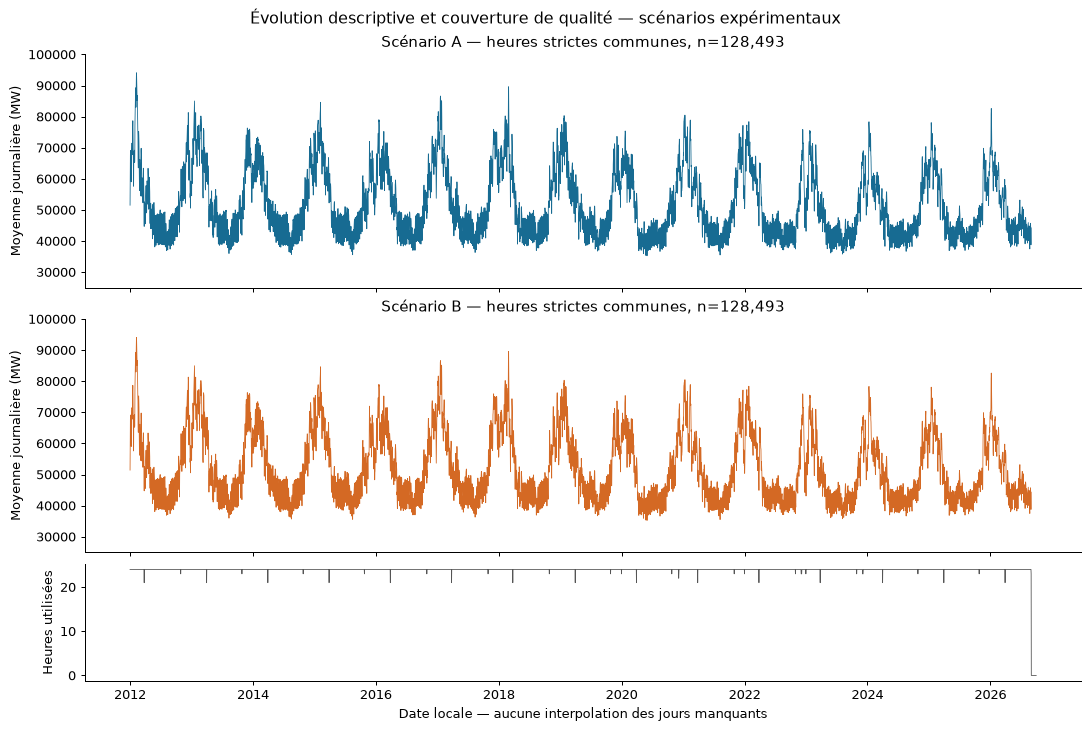

In [7]:
chronology = paired.copy()
chronology.index = chronology.index.tz_convert('Europe/Paris')
daily_means = chronology.resample('D').mean()
daily_n = chronology.resample('D').count()
annual_means = chronology.groupby(chronology.index.year).mean().add_prefix('moyenne MW ')
annual_counts = chronology.groupby(chronology.index.year).count().add_prefix('n utilisé ')
annual_grid = pd.Series(1, index=local_index).groupby(local_index.year).sum().rename('heures dans le fichier')
annual = annual_means.join(annual_counts).join(annual_grid)
annual['exclues (masque commun)'] = annual['heures dans le fichier'] - annual['n utilisé A']
annual['couverture calendaire'] = ['partielle (janvier–septembre)' if year == 2026 else 'année entière, exclusions qualité' for year in annual.index]
display(annual)

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True, constrained_layout=True,
                         gridspec_kw={'height_ratios': [2, 2, 1]})
for axis, scenario in zip(axes[:2], ['A', 'B']):
    axis.plot(daily_means.index, daily_means[scenario], color=COLORS[scenario], linewidth=0.65)
    axis.set_ylabel('Moyenne journalière (MW)')
    axis.set_title(f'Scénario {scenario} — heures strictes communes, n={len(valid):,}')
    axis.set_ylim(25000, 100000)
axes[2].plot(daily_n.index, daily_n['A'], color='#555555', linewidth=0.65)
axes[2].set_ylabel('Heures utilisées')
axes[2].set_xlabel('Date locale — aucune interpolation des jours manquants')
fig.suptitle('Évolution descriptive et couverture de qualité — scénarios expérimentaux', fontsize=13)
plt.show()

## 5. Distribution des puissances

Le tableau donne l'effectif, les exclusions et les statistiques sur les **mêmes heures strictes communes**.
Les quartiles et quantiles sont empiriques avec l'interpolation linéaire de pandas. L'écart-type utilise
`ddof=1`. Les histogrammes ont les mêmes bornes et classes pour A/B et sont normalisés en densité.
La distribution agrège plusieurs saisons et années : elle ne correspond pas à une loi stationnaire.

,count,mean,std,min,1%,25%,50%,75%,99%,max,exclues
scénario,,,,,,,,,,,
A,"128,493.00","52,885.74","11,673.82","28,987.00","32,935.00","44,080.00","51,092.00","60,589.50","82,447.04","101,533.50",793
B,"128,493.00","52,886.05","11,672.15","28,758.00","32,956.46","44,093.00","51,103.00","60,602.50","82,427.28","100,516.00",793


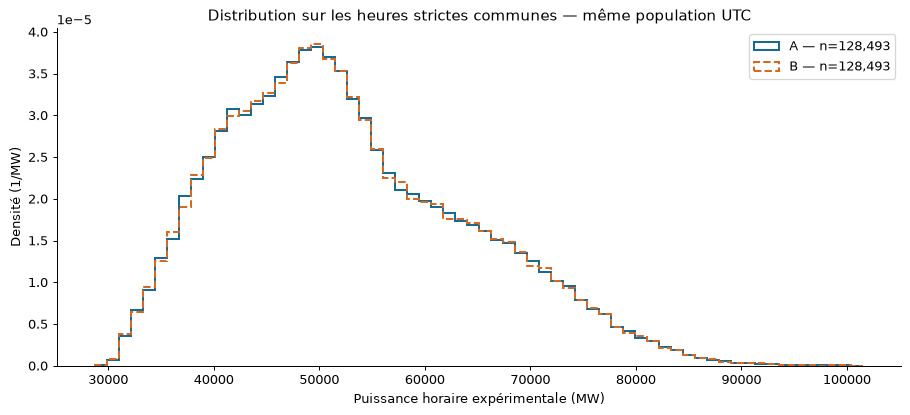

In [8]:
distribution = valid.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
distribution['exclues'] = len(hour_index) - len(valid)
distribution.index.name = 'scénario'
display(distribution)
bins = np.linspace(valid.min().min(), valid.max().max(), 65)
fig, axis = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
for scenario, linestyle in [('A', '-'), ('B', '--')]:
    axis.hist(valid[scenario], bins=bins, density=True, histtype='step', linewidth=1.6,
              linestyle=linestyle, color=COLORS[scenario], label=f'{scenario} — n={len(valid):,}')
axis.set(xlabel='Puissance horaire expérimentale (MW)', ylabel='Densité (1/MW)',
         title='Distribution sur les heures strictes communes — même population UTC')
axis.legend()
plt.show()

## 6. Profils horaires et hebdomadaires

Population : heures strictes communes des années locales **2012–2025**, définies dans le tableau des
populations. Les effectifs sont affichés pour chaque groupe. Les moyennes sont pondérées implicitement
par le nombre d'heures disponibles, sans rééquilibrage par jour ou par année.

Les étiquettes locales répétées à l'automne contribuent deux fois si elles sont toutes deux admissibles ;
les heures inexistantes au printemps ne contribuent pas. Les mois et années peuvent donc avoir des poids
différents. Aucune température, aucun calendrier férié et aucune autre variable externe n'est disponible.

A               B      
                  mean count      mean count
heure locale                                
0            52,238.16  5108 50,201.13  5108
1            49,005.41  5086 48,494.74  5086
2            47,800.75  5100 46,684.88  5100
3            45,501.54  5100 44,711.58  5100
4            44,333.07  5114 44,493.19  5114
5            45,288.71  5114 46,550.84  5114
6            48,259.60  5114 50,223.72  5114
7            52,060.93  5114 53,566.39  5114
8            54,681.41  5114 55,621.21  5114
9            56,407.34  5114 56,944.84  5114
10           57,234.14  5114 57,442.88  5114
11           57,734.84  5114 58,151.93  5114
12           58,386.62  5114 58,321.48  5114
13           57,651.33  5114 56,680.03  5114
14           56,031.82  5114 55,228.14  5114
15           54,336.11  5114 53,661.96  5114
16           53,146.40  5114 52,941.69  5114
17           53,245.49  5114 54,105.36  5114
18           55,304.81  5114 56,565.81  5114
19           57,160.15  5114 56,682.95  5114
20           55,540.05  5114 54,326.70  5114
21           53,340.29  5114 52,645.07  5114
22           52,775.41  5114 53,895.73  5114
23           54,286.90  5105 53,607.65  5105

A                B       
                mean  count      mean  count
jour local                                  
Lundi      53,750.43  17542 53,809.93  17542
Mardi      55,110.69  17541 55,119.31  17541
Mercredi   55,239.98  17543 55,243.51  17543
Jeudi      55,069.60  17520 55,064.98  17520
Vendredi   54,503.39  17518 54,492.97  17518
Samedi     49,738.58  17516 49,697.32  17516
Dimanche   47,512.91  17485 47,500.41  17485

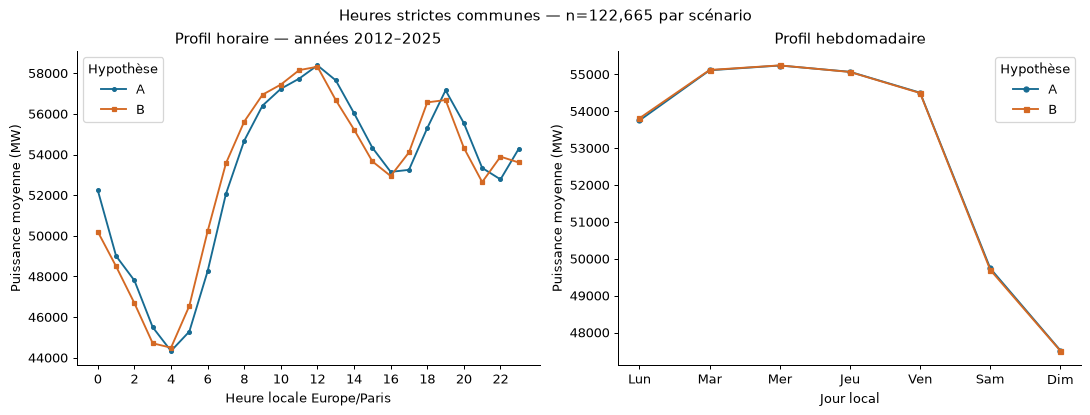

In [9]:
hour_profile = profile_data.groupby(profile_local.hour).agg(['mean', 'count'])
weekday_profile = profile_data.groupby(profile_local.day_of_week).agg(['mean', 'count'])
weekday_names = ['Lundi', 'Mardi', 'Mercredi', 'Jeudi', 'Vendredi', 'Samedi', 'Dimanche']
weekday_profile.index = pd.Index([weekday_names[i] for i in weekday_profile.index], name='jour local')
hour_profile.index.name = 'heure locale'
display(hour_profile)
display(weekday_profile)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
for scenario, marker in [('A', 'o'), ('B', 's')]:
    axes[0].plot(hour_profile.index, hour_profile[(scenario, 'mean')], color=COLORS[scenario],
                 marker=marker, markersize=3, label=scenario)
    axes[1].plot(range(7), weekday_profile[(scenario, 'mean')], color=COLORS[scenario],
                 marker=marker, markersize=4, label=scenario)
axes[0].set(xlabel='Heure locale Europe/Paris', ylabel='Puissance moyenne (MW)', xticks=range(0, 24, 2),
            title='Profil horaire — années 2012–2025')
axes[1].set(xlabel='Jour local', ylabel='Puissance moyenne (MW)', xticks=range(7),
            xticklabels=['Lun', 'Mar', 'Mer', 'Jeu', 'Ven', 'Sam', 'Dim'], title='Profil hebdomadaire')
for axis in axes:
    axis.legend(title='Hypothèse')
fig.suptitle(f'Heures strictes communes — n={len(profile_data):,} par scénario', fontsize=12)
plt.show()

## 7. Profils mensuels, saisonniers et semaine/week-end

Les saisons sont des regroupements de mois : hiver = décembre–janvier–février, printemps = mars–avril–mai,
été = juin–juillet–août, automne = septembre–octobre–novembre. Ce sont des profils regroupés sur 2012–2025,
pas des bilans de saisons continues ni des données météorologiques. Les moyennes restent en MW.

**Lundi–vendredi** est seulement une approximation de la semaine d'activité : les jours fériés et vacances
ne sont pas identifiés. Le contraste avec samedi–dimanche ne doit pas être présenté comme un effet causal
du travail ou comme une classification exacte des jours ouvrés.

A                B       
                    mean  count      mean  count
hour_start_utc                                  
1              68,516.49  10416 68,518.76  10416
2              66,518.14   9504 66,518.10   9504
3              58,571.65  10374 58,566.55  10374
4              50,607.51  10080 50,603.56  10080
5              45,169.41  10416 45,166.89  10416
6              44,562.23  10080 44,562.43  10080
7              45,006.52  10416 45,005.54  10416
8              42,111.58  10416 42,111.43  10416
9              44,904.02  10080 44,905.07  10080
10             48,654.78  10402 48,659.46  10402
11             58,094.80  10080 58,103.91  10080
12             63,957.74  10401 63,958.39  10401

A                B       
               mean  count      mean  count
Hiver     66,326.33  30321 66,327.32  30321
Printemps 51,449.00  30870 51,445.14  30870
Été       43,886.18  30912 43,885.86  30912
Automne   50,531.22  30562 50,536.16  30562

A                B       
                     mean  count      mean  count
Lundi–vendredi  54,734.80  87664 54,746.13  87664
Samedi–dimanche 48,626.73  35001 48,599.84  35001

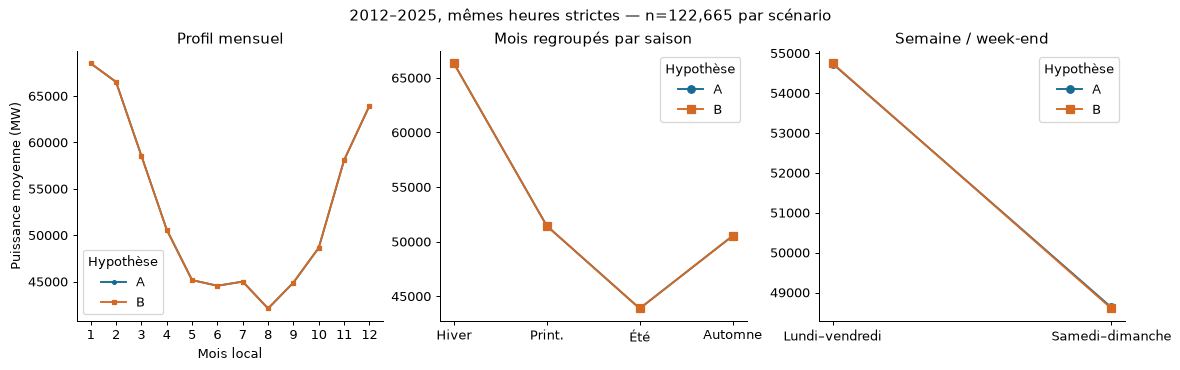

In [10]:
monthly_profile = profile_data.groupby(profile_local.month).agg(['mean', 'count'])
season_labels = pd.Index(np.select([np.isin(profile_local.month, [12, 1, 2]),
                                   np.isin(profile_local.month, [3, 4, 5]),
                                   np.isin(profile_local.month, [6, 7, 8])],
                                  ['Hiver', 'Printemps', 'Été'], default='Automne'))
season_profile = profile_data.groupby(season_labels).agg(['mean', 'count']).reindex(['Hiver', 'Printemps', 'Été', 'Automne'])
week_labels = pd.Index(np.where(profile_local.day_of_week < 5, 'Lundi–vendredi', 'Samedi–dimanche'))
week_profile = profile_data.groupby(week_labels).agg(['mean', 'count'])
display(monthly_profile)
display(season_profile)
display(week_profile)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
for scenario, marker in [('A', 'o'), ('B', 's')]:
    axes[0].plot(monthly_profile.index, monthly_profile[(scenario, 'mean')], marker=marker,
                 color=COLORS[scenario], label=scenario, markersize=3)
    axes[1].plot(range(4), season_profile[(scenario, 'mean')], marker=marker,
                 color=COLORS[scenario], label=scenario)
    axes[2].plot(range(2), week_profile[(scenario, 'mean')], marker=marker,
                 color=COLORS[scenario], label=scenario)
axes[0].set(xlabel='Mois local', xticks=range(1, 13), title='Profil mensuel', ylabel='Puissance moyenne (MW)')
axes[1].set(xticks=range(4), xticklabels=['Hiver', 'Print.', 'Été', 'Automne'], title='Mois regroupés par saison')
axes[2].set(xticks=range(2), xticklabels=week_profile.index.tolist(), title='Semaine / week-end')
for axis in axes:
    axis.legend(title='Hypothèse')
fig.suptitle(f'2012–2025, mêmes heures strictes — n={len(profile_data):,} par scénario', fontsize=12)
plt.show()

## 8. Comparaison des scénarios : alignement et disponibilité

À la même heure h, les hypothèses utilisent respectivement les étiquettes (h, h+30 min) et (h+30 min, h+1 h).
La différence B−A n'est donc pas une erreur de prévision. Quand les trois valeurs sont résolues,
elle reflète notamment la variation entre les deux étiquettes extrêmes de cette fenêtre.
Un changement de profil horaire est compatible avec cet alignement, sans prouver sa validité physique.

Le premier tableau distingue les masques et leurs exclusions. Le second décompose **arithmétiquement**
l'écart entre moyennes sur masques propres en écart sur population commune et reliquat de sélection.
Ce reliquat ne constitue pas une estimation causale de l'effet des données manquantes.
Le profil B−A est calculé sur les heures communes des années 2012–2025, et non sur deux populations différentes.

,n apparié,exclues,moyenne A (MW),moyenne B (MW),moyenne B−A (MW),médiane |B−A| (MW),maximum |B−A| (MW)
population,,,,,,,
Calculables communes,129227,59,"52,832.50","52,832.78",0.28,763.50,"4,684.50"
Strictes communes,128493,793,"52,885.74","52,886.05",0.32,764.00,"4,684.50"


,écart des moyennes sur masques propres (MW),écart sur heures strictes communes (MW),reliquat de sélection (MW)
0,1.31,0.32,0.99


,mean,median,count
hour_start_utc,,,
0,"-2,037.02","-2,171.00",5108
1,-510.68,-563.50,5086
2,"-1,115.87","-1,098.00",5100
3,-789.96,-797.00,5100
4,160.12,120.00,5114
5,"1,262.14","1,299.50",5114
6,"1,964.11","2,113.75",5114
7,"1,505.46","1,503.50",5114
8,939.80,"1,024.00",5114


,scénario,heure locale du maximum moyen (masque commun),heure locale du maximum moyen (masque propre),n masque propre 2012–2025,n masque commun
0,A,12,12,122702,122665
1,B,12,12,122671,122665


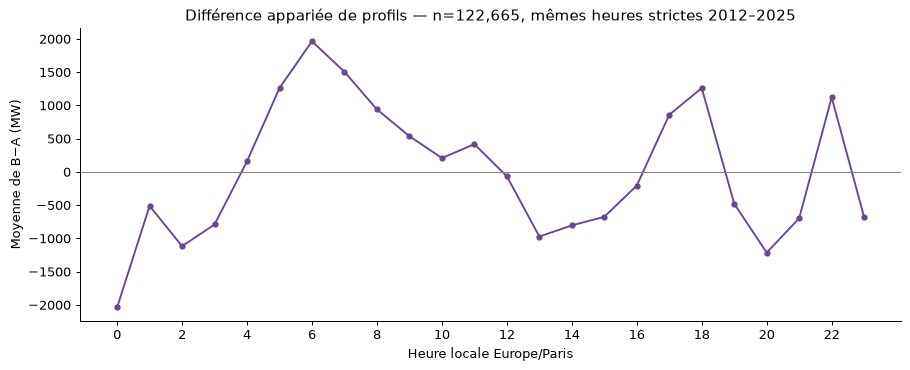

In [11]:
sensitivity_rows = []
for label, mask in [('Calculables communes', common_computable), ('Strictes communes', common_strict)]:
    sample = powers.loc[mask]
    delta = sample['B'] - sample['A']
    sensitivity_rows.append({'population': label, 'n apparié': len(sample),
                             'exclues': len(hour_index) - len(sample),
                             'moyenne A (MW)': sample['A'].mean(), 'moyenne B (MW)': sample['B'].mean(),
                             'moyenne B−A (MW)': delta.mean(), 'médiane |B−A| (MW)': delta.abs().median(),
                             'maximum |B−A| (MW)': delta.abs().max()})
sensitivity = pd.DataFrame(sensitivity_rows).set_index('population')
display(sensitivity)
own_means = {scenario: frame.loc[frame['target_eligible_strict'], 'electricity_mw'].mean()
             for scenario, frame in frames.items()}
own_difference = own_means['B'] - own_means['A']
common_difference = valid['B'].mean() - valid['A'].mean()
display(pd.DataFrame([{'écart des moyennes sur masques propres (MW)': own_difference,
                       'écart sur heures strictes communes (MW)': common_difference,
                       'reliquat de sélection (MW)': own_difference - common_difference}]))

profile_difference = (profile_data['B'] - profile_data['A']).groupby(profile_local.hour).agg(['mean', 'median', 'count'])
display(profile_difference)
peak_rows = []
for scenario, frame in frames.items():
    own_mask = frame['target_eligible_strict'].astype(bool) & full_years
    own_profile = frame.loc[own_mask, 'electricity_mw'].groupby(local_index[own_mask].hour).mean()
    peak_rows.append({'scénario': scenario, 'heure locale du maximum moyen (masque commun)': int(hour_profile[(scenario, 'mean')].idxmax()),
                      'heure locale du maximum moyen (masque propre)': int(own_profile.idxmax()),
                      'n masque propre 2012–2025': int(own_mask.sum()), 'n masque commun': len(profile_data)})
display(pd.DataFrame(peak_rows))
fig, axis = plt.subplots(figsize=(10, 4), constrained_layout=True)
axis.plot(profile_difference.index, profile_difference['mean'], color='#6a4591', marker='o', markersize=4)
axis.axhline(0, color='gray', linewidth=0.8)
axis.set(xlabel='Heure locale Europe/Paris', ylabel='Moyenne de B−A (MW)', xticks=range(0, 24, 2),
         title=f'Différence appariée de profils — n={len(profile_data):,}, mêmes heures strictes 2012–2025')
plt.show()

## 9. Valeurs extrêmes : description et provenance

Pour chaque scénario, les cinq minima et cinq maxima sont identifiés sur les **heures strictes communes**
de toute la période. Les dates UTC/locales et les positions des observations sources sont conservées.
En cas d'égalité, le tri stable conserve l'ordre temporel. Cette sélection descriptive ne supprime aucune
observation. Une forte ou faible puissance ne constitue pas à elle seule une erreur de mesure.
Les extrêmes non stricts éventuellement présents ne sont pas inclus dans ce classement principal.

In [12]:
extreme_parts = []
for scenario in ['A', 'B']:
    for kind, selected in [('Cinq minima', valid[scenario].sort_values(kind='stable').head(5)),
                           ('Cinq maxima', valid[scenario].sort_values(ascending=False, kind='stable').head(5))]:
        view = pd.DataFrame({'scénario': scenario, 'sélection': kind,
                             'heure début UTC': selected.index.astype(str),
                             'heure début locale': selected.index.tz_convert('Europe/Paris').astype(str),
                             'puissance MW': selected.to_numpy(),
                             'positions sources (deux composantes)': frames[scenario].loc[selected.index, 'source_positions'].to_numpy()})
        extreme_parts.append(view)
extremes = pd.concat(extreme_parts, ignore_index=True)
display(extremes)
display(Markdown('Les valeurs ci-dessus sont des extrêmes **dans la population retenue** ; aucune qualification automatique d’erreur ni suppression n’est appliquée.'))

,scénario,sélection,heure début UTC,heure début locale,puissance MW,positions sources (deux composantes)
0,A,Cinq minima,2020-05-10 05:00:00+00:00,2020-05-10 07:00:00+02:00,"28,987.00","[[112066],[112065]]"
1,A,Cinq minima,2020-05-31 04:00:00+00:00,2020-05-31 06:00:00+02:00,"29,036.00","[[111060],[111059]]"
2,A,Cinq minima,2020-05-10 04:00:00+00:00,2020-05-10 06:00:00+02:00,"29,120.00","[[112068],[112067]]"
3,A,Cinq minima,2020-05-24 04:00:00+00:00,2020-05-24 06:00:00+02:00,"29,437.00","[[111396],[111395]]"
4,A,Cinq minima,2020-05-31 05:00:00+00:00,2020-05-31 07:00:00+02:00,"29,666.00","[[111058],[111057]]"
5,A,Cinq maxima,2012-02-08 18:00:00+00:00,2012-02-08 19:00:00+01:00,"101,533.50","[[256714],[256713]]"
6,A,Cinq maxima,2012-02-07 18:00:00+00:00,2012-02-07 19:00:00+01:00,"100,217.00","[[256762],[256761]]"
7,A,Cinq maxima,2012-02-08 09:00:00+00:00,2012-02-08 10:00:00+01:00,"99,887.50","[[256732],[256731]]"
8,A,Cinq maxima,2012-02-08 10:00:00+00:00,2012-02-08 11:00:00+01:00,"99,698.00","[[256730],[256729]]"
9,A,Cinq maxima,2012-02-08 11:00:00+00:00,2012-02-08 12:00:00+01:00,"99,432.00","[[256728],[256727]]"


Les valeurs ci-dessus sont des extrêmes **dans la population retenue** ; aucune qualification automatique d’erreur ni suppression n’est appliquée.

## 10. Constats descriptifs et questions avant la modélisation

Les valeurs de la synthèse suivante sont calculées par les cellules précédentes. Les différences de
niveau entre années, mois et jours ne permettent pas de séparer les effets des activités, températures,
changements structurels et règles de qualité : aucune variable externe n'a été chargée.

In [13]:
summary_lines = [f'- Base principale : **{len(valid):,} heures strictes communes** ; '
                 f'**{len(hour_index) - len(valid):,} heures exclues** de la grille commune.',
                 f'- Profils calendaires 2012–2025 : **{len(profile_data):,} heures** par scénario ; '
                 'les observations de 2026 sont exclues de ces seuls profils.']
for scenario in ['A', 'B']:
    seasonal = season_profile[(scenario, 'mean')]
    hourly = hour_profile[(scenario, 'mean')]
    weekly = weekday_profile[(scenario, 'mean')]
    summary_lines.extend([
        f'- **{scenario}** : moyenne sur base principale **{valid[scenario].mean():,.1f} MW** ; '
        f'minimum **{valid[scenario].min():,.1f} MW**, maximum **{valid[scenario].max():,.1f} MW**.',
        f'- **{scenario}, profils 2012–2025** : maximum du profil horaire à **{int(hourly.idxmax()):02d}:00 locale** ; '
        f'profil saisonnier le plus élevé en **{seasonal.idxmax()}**, le plus bas en **{seasonal.idxmin()}** ; '
        f'jour moyen le plus bas : **{weekly.idxmin()}**.',
    ])
display(Markdown('\n'.join(summary_lines)))
display(Markdown('''
Les variations horaires, hebdomadaires et saisonnières décrites constituent des pistes pour la future
prévision à 24 heures, sans démonstration de causalité ni résultat prédictif. Les tableaux d’effectifs
et les masques doivent accompagner toute réutilisation de ces constats.

**Questions à résoudre :**

1. Confirmer les conventions physiques, les supports et leur stabilité, sans sélectionner A/B sur leur apparence.
2. Fixer l’origine de prévision et distinguer 24 heures UTC écoulées du lendemain civil local à 23/24/25 heures.
3. Établir quelles consommations et révisions étaient effectivement disponibles à chaque origine historique.
4. Définir à l’avance les exclusions de qualité et une analyse de sensibilité ; ne pas imputer les cibles d’évaluation.
5. Choisir un découpage chronologique tenant compte de la non-stationnarité et des années consolidées.
6. Décider ultérieurement de variables calendaires, d’historiques et de sources météo prévisionnelles justifiées.

Aucun jeu de variables prédictives, modèle, découpage appris ou prévision n’est créé ici. Les EDA devront
rester distinctes de la future évaluation confirmatoire ; les choix ultérieurs et leur origine exploratoire
devront être documentés pour ne pas présenter un test déjà exploré comme entièrement inédit.
'''))

- Base principale : **128,493 heures strictes communes** ; **793 heures exclues** de la grille commune.
- Profils calendaires 2012–2025 : **122,665 heures** par scénario ; les observations de 2026 sont exclues de ces seuls profils.
- **A** : moyenne sur base principale **52,885.7 MW** ; minimum **28,987.0 MW**, maximum **101,533.5 MW**.
- **A, profils 2012–2025** : maximum du profil horaire à **12:00 locale** ; profil saisonnier le plus élevé en **Hiver**, le plus bas en **Été** ; jour moyen le plus bas : **Dimanche**.
- **B** : moyenne sur base principale **52,886.1 MW** ; minimum **28,758.0 MW**, maximum **100,516.0 MW**.
- **B, profils 2012–2025** : maximum du profil horaire à **12:00 locale** ; profil saisonnier le plus élevé en **Hiver**, le plus bas en **Été** ; jour moyen le plus bas : **Dimanche**.


Les variations horaires, hebdomadaires et saisonnières décrites constituent des pistes pour la future
prévision à 24 heures, sans démonstration de causalité ni résultat prédictif. Les tableaux d’effectifs
et les masques doivent accompagner toute réutilisation de ces constats.

**Questions à résoudre :**

1. Confirmer les conventions physiques, les supports et leur stabilité, sans sélectionner A/B sur leur apparence.
2. Fixer l’origine de prévision et distinguer 24 heures UTC écoulées du lendemain civil local à 23/24/25 heures.
3. Établir quelles consommations et révisions étaient effectivement disponibles à chaque origine historique.
4. Définir à l’avance les exclusions de qualité et une analyse de sensibilité ; ne pas imputer les cibles d’évaluation.
5. Choisir un découpage chronologique tenant compte de la non-stationnarité et des années consolidées.
6. Décider ultérieurement de variables calendaires, d’historiques et de sources météo prévisionnelles justifiées.

Aucun jeu de variables prédictives, modèle, découpage appris ou prévision n’est créé ici. Les EDA devront
rester distinctes de la future évaluation confirmatoire ; les choix ultérieurs et leur origine exploratoire
devront être documentés pour ne pas présenter un test déjà exploré comme entièrement inédit.


## 11. Vérification finale

Cette cellule relit les empreintes des quatre fichiers d'entrée. Aucun fichier brut ou préparé n'a été écrit.
Les statistiques et figures précédentes sont des résultats descriptifs de cet instantané et de ses masques,
non une validation des conventions physiques ou des performances d'une méthode de prévision.

In [14]:
for relative, expected in expected_hashes.items():
    with (ROOT / relative).open('rb') as stream:
        assert hashlib.file_digest(stream, 'sha256').hexdigest() == expected, relative
print('Quatre empreintes conformes après analyse ; aucune imputation, aucune donnée préparée régénérée.')
print('Aucun modèle entraîné, aucune prévision produite.')

Quatre empreintes conformes après analyse ; aucune imputation, aucune donnée préparée régénérée.
Aucun modèle entraîné, aucune prévision produite.
